# 07 · Ethics, safety and critical cartography

A map of people in a contested place can protect them or endanger them. Balochistan has a long record of armed
conflict, enforced disappearances, surveillance and restrictions on journalists and researchers. Treat every
location of a person, home, meeting or event involving identifiable people as sensitive data.

## A checklist before you collect, map or share

| Stage | Ask | Do |
|---|---|---|
| Plan | Who could use this map, and against whom? | Write a short data-protection plan; discuss it with your ethics board and with participants |
| Consent | Did people agree to be *mapped*, not only interviewed? At what precision? | Record the precision each person agreed to |
| Collect | Does my phone add locations to photos and notes? | Turn off location tagging; strip EXIF metadata (below); use pseudonyms from the start |
| Store | Who can open my files if my phone or laptop is taken? | Encrypt (VeraCrypt, BitLocker, FileVault); keep field data offline; separate the key linking pseudonyms to names |
| Analyse | Do I need exact points? | Work with areas, grids or jittered points; keep exact data off cloud services, including Colab |
| Publish | Could a reader find a person or home from this map? | Aggregate (district, grid), suppress small counts, coarsen, delay; never publish home locations of participants |
| Share code | Does the notebook contain real data, keys or names? | Share code with made-up data; keep keys in environment variables |

## Strip the hidden location from a photograph

*Running this in Google Colab?* The next cell installs the few libraries Colab lacks (about a minute). Notebooks
04-07 read files made by 01 and 02: run those first in the same session, or keep the `data` folder on Google Drive.

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx", "overturemaps", "mapclassify", "esda", "libpysal", "folium", "plotly"], check=True)

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from PIL import Image
DATA, CRS = Path("data"), 32642
img = Image.new("RGB", (60, 40), "grey"); exif = img.getexif(); exif[0x8825] = {2: (30.0, 11.0, 0.0), 4: (67.0, 1.0, 0.0)}
img.save(DATA / "photo_with_gps.jpg", exif=exif)                          # a test photo carrying a GPS position

def strip_metadata(src, dst):
    """Save a copy of an image without any EXIF metadata (GPS position, camera, time)."""
    im = Image.open(src); clean = Image.new(im.mode, im.size); clean.putdata(list(im.getdata())); clean.save(dst)
strip_metadata(DATA / "photo_with_gps.jpg", DATA / "photo_clean.jpg")
for f in ["photo_with_gps.jpg", "photo_clean.jpg"]:
    print(f, "-> GPS present:", 0x8825 in Image.open(DATA / f).getexif())

photo_with_gps.jpg -> GPS present: True
photo_clean.jpg -> GPS present: False


## Protecting locations: three techniques, side by side
Made-up "participant homes" in Quetta, shown exact, jittered, snapped to a grid and aggregated with small counts
suppressed.

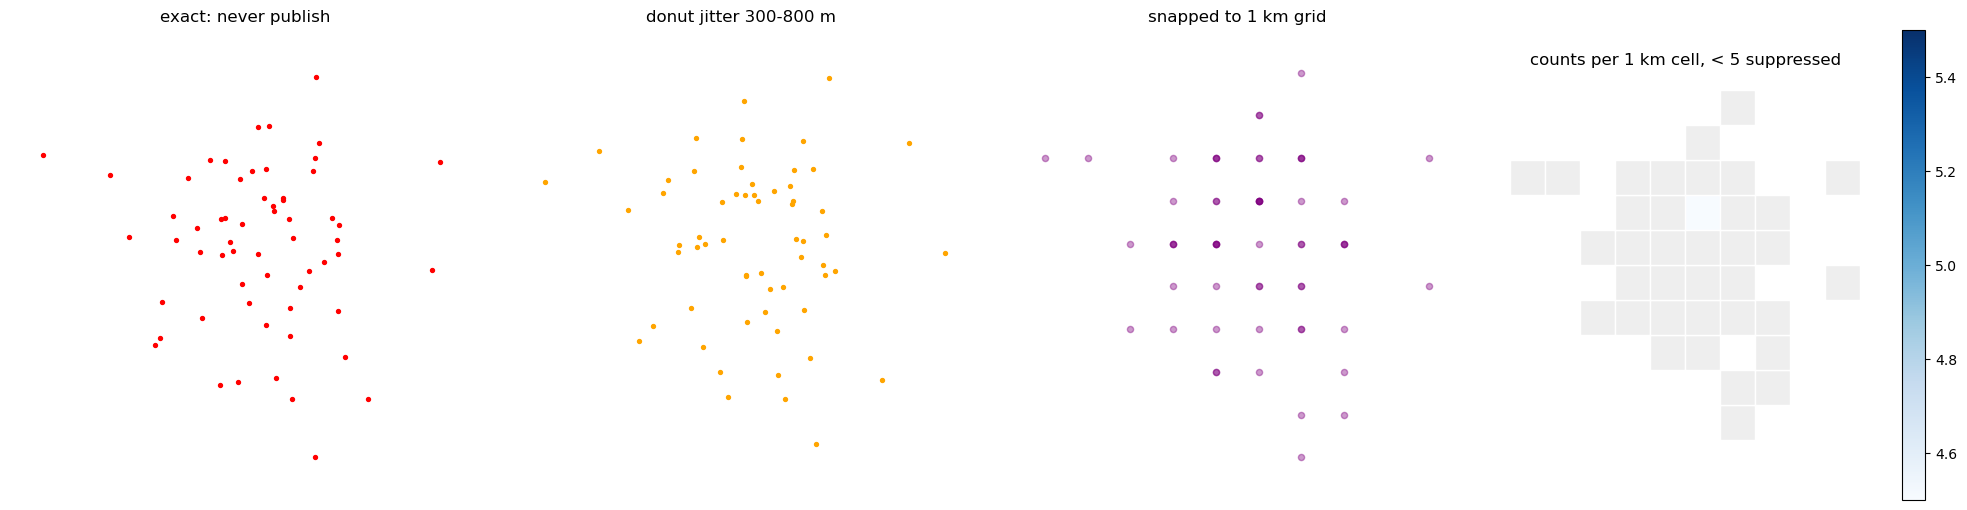

In [3]:
rng = np.random.default_rng(1)
homes = gpd.GeoDataFrame(geometry=gpd.points_from_xy(67.0 + rng.normal(0, .02, 60), 30.19 + rng.normal(0, .02, 60)), crs=4326).to_crs(CRS)
jit = homes.copy(); ang, r = rng.uniform(0, 2 * np.pi, len(jit)), rng.uniform(300, 800, len(jit))
jit["geometry"] = gpd.points_from_xy(jit.geometry.x + r * np.cos(ang), jit.geometry.y + r * np.sin(ang))   # donut jitter: at least 300 m away
S = 1000
snap = homes.copy(); snap["geometry"] = gpd.points_from_xy((homes.geometry.x // S + .5) * S, (homes.geometry.y // S + .5) * S)
cnt = snap.groupby([snap.geometry.x, snap.geometry.y]).size().rename("n").reset_index()
from shapely.geometry import box
cells = gpd.GeoDataFrame(cnt, geometry=[box(x - S / 2, y - S / 2, x + S / 2, y + S / 2) for x, y in zip(cnt.iloc[:, 0], cnt.iloc[:, 1])], crs=CRS)
cells["shown"] = np.where(cells.n >= 5, cells.n, np.nan)                    # suppress cells with fewer than 5
fig, ax = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
homes.plot(ax=ax[0], color="red", markersize=8); ax[0].set_title("exact: never publish")
jit.plot(ax=ax[1], color="orange", markersize=8); ax[1].set_title("donut jitter 300-800 m")
snap.plot(ax=ax[2], color="purple", markersize=20, alpha=.4); ax[2].set_title("snapped to 1 km grid")
cells.plot(ax=ax[3], column="shown", cmap="Blues", legend=True, missing_kwds={"color": "#eee", "label": "< 5 hidden"}, edgecolor="white")
ax[3].set_title("counts per 1 km cell, < 5 suppressed")
for a in ax: a.set_axis_off()
plt.tight_layout()

Jitter alone can be undone if the same people are published twice with different jitter, or if few buildings lie
nearby: prefer aggregation for anything public, and keep the exact data encrypted and offline.

## Critical cartography: the same data, different claims
**Borders.** Pakistan's border with Afghanistan (the Durand Line) is not recognised by Afghanistan; parts of
Balochistan's history (the Khanate of Kalat, its accession in 1948) are contested. A boundary file encodes one
government's view. Say whose boundaries you use (here: OCHA/HDX, following Pakistan's official lines) and consider
showing contested lines as dashed.

**Names.** Baluchistan or Balochistan; Kalat state or Kalat district; the name an armed group is given by the state,
by UCDP, by its supporters. Choose deliberately and say why.

**Classes and colours.** Below, the same UCDP events by district: raw counts in alarming red, and rates per
population in a neutral sequential palette with stated classes. Neither is false; they make different arguments.

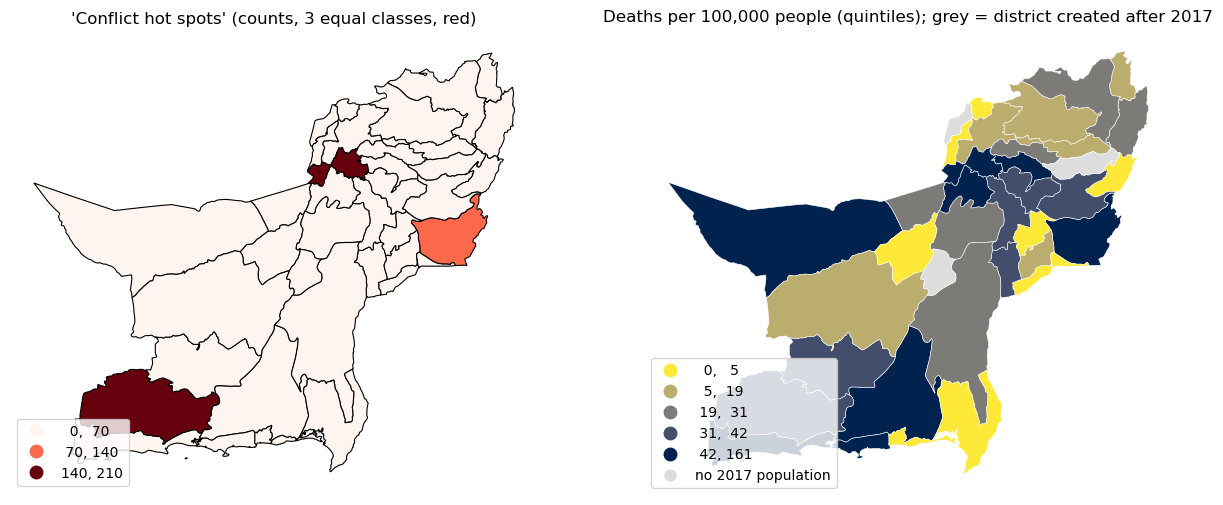

In [4]:
d = gpd.read_file(DATA / "bal_districts.gpkg")
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
d.plot("events", ax=ax[0], cmap="Reds", scheme="EqualInterval", k=3, legend=True, edgecolor="black", lw=.8, legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
ax[0].set_title("'Conflict hot spots' (counts, 3 equal classes, red)")
d.plot("deaths_per_100k", ax=ax[1], cmap="cividis_r", scheme="Quantiles", k=5, legend=True, edgecolor="white", lw=.4, missing_kwds={"color": "#ddd", "label": "no 2017 population"},
       legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
ax[1].set_title("Deaths per 100,000 people (quintiles); grey = district created after 2017")
for a in ax: a.set_axis_off()

**What is absent.** UCDP counts deaths it can verify from published sources; Balochistan is under-reported because
journalists' access is restricted. Enforced disappearances, arrests, protests and internet shutdowns, which many
residents describe as central to political life, are not in it. Sources that document them (human-rights
commissions, the Voice for Baloch Missing Persons, Amnesty International, HRCP reports) are lists and reports, not
clean datasets; mapping them requires the care above and their authors' consent.

**Who is on the open map.** In notebook 01, OpenStreetMap had 889 buildings for Quetta against Overture's 254,056,
and about 50 places of worship. Maps made from open data show the province as emptier than it is. Write this into
the caption of every map, not only the methods section.

## Further reading
- Harley, J.B. (1989) Deconstructing the map. *Cartographica* 26(2).
- Crampton, J. and Krygier, J. (2005) An introduction to critical cartography. *ACME* 4(1).
- Elwood, S. (2008) Volunteered geographic information: future research directions. *GeoJournal* 72.
- Kwan, M.-P. (2002) Feminist visualization: re-envisioning GIS as a method in feminist geographic research. *Annals of the AAG* 92(4).
- Zook, M. et al. (2017) Ten simple rules for responsible big data research. *PLoS Comput Biol* 13(3).
- Responsible Data (responsibledata.io) and the ICRC Handbook on Data Protection in Humanitarian Action (2nd ed., 2020).